# Week 1: Reading hardware in a notebook

**Goal for today:** get comfortable. You will run cells, look at pictures of circuits, and change a few things. Nothing here needs to be written from scratch.

How to use this notebook:
- Click a cell and press **Shift + Enter** to run it.
- Run the cells from top to bottom.
- If something breaks, ask a helper. Breaking things is fine.

## Step 0: Install the tools (run once)
Run the next cell once. It installs Yosys and ipywidgets into the Python this notebook is using, then tries to install netlistsvg (this needs Node.js).

If the last line says npm was not found, install Node.js (the LTS version) from nodejs.org, restart VSCode, and run this cell again.

In [4]:
%pip install -q yowasp-yosys ipywidgets
!npm install -g netlistsvg

Note: you may need to restart the kernel to use updated packages.

changed 71 packages in 9s

5 packages are looking for funding
  run `npm fund` for details


## Step 1: Check your setup
Run the cell below. Every line should show a green check. If a line shows an X, the install tip next to it tells you what to do.

In [5]:
import subprocess, shutil, sys, os
from IPython.display import SVG, display

def _find(names):
    base = os.path.dirname(sys.executable)
    folders = [None, base, os.path.join(base, "Scripts"), os.path.join(base, "Library", "bin")]
    for n in names:
        for path in folders:
            p = shutil.which(n, path=path)
            if p:
                return p
    return None

_BOOT = "\n".join([
    "import sys, yowasp_yosys as y",
    "f = getattr(y, 'run_yosys', None)",
    "if f is not None:",
    "    sys.exit(f(sys.argv[1:]) or 0)",
    "f = getattr(y, '_run_yosys_argv', None)",
    "if f is not None:",
    "    sys.exit(f() or 0)",
    "print('yowasp_yosys has no runner. Contents:', dir(y))",
    "sys.exit(1)",
])

def _yosys_cmd():
    exe = _find(["yowasp-yosys", "yosys"])
    if exe:
        return [exe]
    try:
        import yowasp_yosys
        return [sys.executable, "-c", _BOOT]
    except Exception:
        return None

YOSYS = _yosys_cmd()
NETLISTSVG = _find(["netlistsvg"])
IVERILOG = _find(["iverilog"])

def _has_module(name):
    try:
        __import__(name)
        return True
    except Exception:
        return False

checks = [
    ("Yosys (reads Verilog)",        YOSYS is not None,        "pip install yowasp-yosys"),
    ("netlistsvg (draws schematics)", NETLISTSVG is not None,   "install Node.js, then: npm install -g netlistsvg"),
    ("ipywidgets (buttons)",          _has_module("ipywidgets"), "pip install ipywidgets"),
    ("Icarus Verilog (needed later)", IVERILOG is not None,     "optional for week 1"),
]
for label, ok, tip in checks:
    print(("[OK]  " if ok else "[X]   ") + label + ("" if ok else "   ->  " + tip))

[OK]  Yosys (reads Verilog)
[OK]  netlistsvg (draws schematics)
[OK]  ipywidgets (buttons)
[OK]  Icarus Verilog (needed later)


## Step 2: A helper that draws schematics
This cell defines `show_schematic`. It gives Yosys some Verilog, then draws the result as a picture, like the RTL schematic in Vivado. You do not need to read the code inside. Just run it.

In [6]:
def show_schematic(verilog, top, name="design"):
    """Turn Verilog code into a schematic picture."""
    if YOSYS is None or NETLISTSVG is None:
        print("Yosys or netlistsvg is missing. Re-run Step 1 and follow the install tips.")
        return
    os.makedirs("build", exist_ok=True)
    v, j, s = f"build/{name}.v", f"build/{name}.json", f"build/{name}.svg"
    with open(v, "w") as f:
        f.write(verilog)
    r = subprocess.run([*YOSYS, "-q", "-p", f"read_verilog -sv {v}; prep -top {top}; write_json {j}"],
                       capture_output=True, text=True)
    if r.returncode != 0:
        print("Yosys found a problem in your code:\n")
        print(r.stderr or r.stdout)
        return
    if r.stderr.strip():
        print("Yosys warnings:\n" + r.stderr)
    r = subprocess.run([NETLISTSVG, j, "-o", s], capture_output=True, text=True)
    if r.returncode != 0:
        print("netlistsvg could not draw this:\n" + (r.stderr or r.stdout))
        return
    display(SVG(filename=s))

## Step 3: Your first schematic
This is a **module**. It is a box with inputs and outputs. Inside, one line says `y` equals `a AND b`.

Run the cell and look at the picture. You should see two inputs going into an AND gate.

Yosys warnings:
Preparing to run yowasp-yosys. This might take a while...



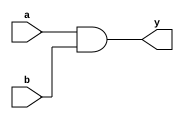

In [7]:
and_gate = """
module and_gate(input a, input b, output y);
    assign y = a & b;
endmodule
"""
show_schematic(and_gate, "and_gate", "and_gate")

## Step 4: Change one thing
In the cell below, change `&` to `|` (the symbol for OR), then run it again.

**Question:** what do you expect the picture to look like? Decide first, then run it.

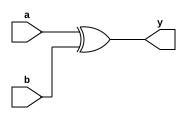

In [11]:
my_gate = """
module my_gate(input a, input b, output y);
    assign y = a ^ b;   // <-- change & to |
endmodule
"""
show_schematic(my_gate, "my_gate", "my_gate")

## Step 5: Predict, then reveal
Here is a **mux** (multiplexer). It picks between two inputs. Read the code and **guess the picture on paper** (or in your head) before running the cell.

Hints:
- `sel ? b : a` means: if `sel` is 1, pick `b`, otherwise pick `a`.
- How many inputs will the picture have?

In [ ]:
mux2 = """
module mux2(input a, input b, input sel, output y);
    assign y = sel ? b : a;
endmodule
"""
show_schematic(mux2, "mux2", "mux2")

**Check yourself:** did you guess a box with a select line? Hardware that "chooses" is one of the most common shapes you will see.

## Step 6: Something that remembers
So far everything was just gates. A **flip-flop** stores a value and only updates on a clock edge. This is a 4-bit counter. Run it and find the flip-flop (the box with a small triangle for the clock).

In [ ]:
counter = """
module counter(input clk, input reset, output reg [3:0] count);
    always @(posedge clk) begin
        if (reset)
            count <= 4'd0;
        else
            count <= count + 4'd1;
    end
endmodule
"""
show_schematic(counter, "counter", "counter")

Things to notice:
- The **+1** is an adder.
- The **reset** decides between 0 and the new value (a mux again).
- The **flip-flop** holds the result until the next clock edge.

This counter is a tiny version of the program counter in your CPU.

## Step 7: A tiny instruction set (ISA)
An **ISA** is the list of instructions a CPU understands. Here is a tiny one with only two instructions:

| Instruction | Meaning |
|---|---|
| `LOAD Rx, n` | put the number `n` into register `Rx` |
| `ADD Rx, Ry` | `Rx = Rx + Ry` |

Run the cell to see the program, then **trace it by hand** before checking.

In [ ]:
program = [
    ("LOAD", "R0", 5),
    ("LOAD", "R1", 3),
    ("ADD",  "R0", "R1"),
    ("ADD",  "R0", "R0"),
]
for i, line in enumerate(program):
    print(i, line)

**Your turn:** what is `R0` at the end? Type your guess below and run the cell.

In [ ]:
my_guess = 0   # <-- change this number to your guess

def run(program):
    regs = {"R0": 0, "R1": 0}
    for op, a, b in program:
        if op == "LOAD":
            regs[a] = b
        elif op == "ADD":
            regs[a] = regs[a] + regs[b]
    return regs

final = run(program)
if my_guess == final["R0"]:
    print("Correct! R0 =", final["R0"])
else:
    print("Not quite. Trace the program one line at a time and try again.")

Want to see the answer line by line? Run this cell.

In [ ]:
regs = {"R0": 0, "R1": 0}
for op, a, b in program:
    if op == "LOAD":
        regs[a] = b
    elif op == "ADD":
        regs[a] = regs[a] + regs[b]
    print(f"{op} {a}, {b}   ->   {regs}")

## Wrap-up
Today you:
- ran Verilog and saw it turn into a schematic,
- changed a gate and saw the picture change,
- met a mux and a flip-flop,
- traced a tiny program on a tiny ISA.

**For your own ISA, think about:** which instructions would you want? What would be the hardest one to build out of gates? Bring your ideas to the next session.

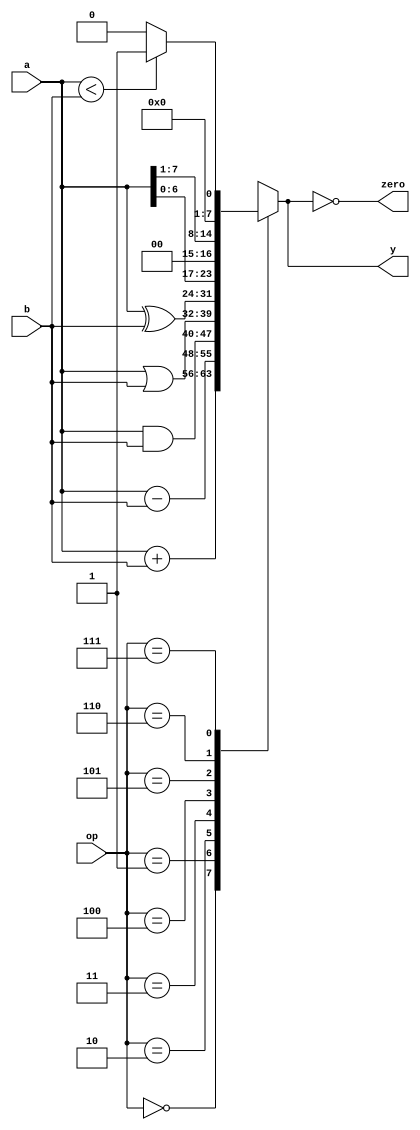

In [12]:
alu = """
module alu(
    input  logic [7:0] a,
    input  logic [7:0] b,
    input  logic [2:0] op,
    output logic [7:0] y,
    output logic       zero
);
    always_comb begin
        case (op)
            3'd0: y = a + b;
            3'd1: y = a - b;
            3'd2: y = a & b;
            3'd3: y = a | b;
            3'd4: y = a ^ b;
            3'd5: y = a << 1;
            3'd6: y = a >> 1;
            3'd7: y = (a < b) ? 8'd1 : 8'd0;
            default: y = 8'd0;
        endcase
    end
    assign zero = (y == 8'd0);
endmodule
"""
show_schematic(alu, "alu", "alu")